In [44]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2

training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

train_dataloader = DataLoader(training_data, batch_size=64,shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64,shuffle=True)

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512,10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork()

In [45]:
learning_rate = 1e-3
batch_size = 64
epochs = 10
# Initialize the loss function
loss_fn = nn.CrossEntropyLoss()

In [46]:
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [47]:
def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    # Set the model to training mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        # Compute prediction and loss
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


In [48]:
def test_loop(dataloader, model, loss_fn):
    # Set the model to evaluation mode - important for batch normalization and dropout layers
    # Unnecessary in this situation but added for best practices
    model.eval()
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Evaluating the model with torch.no_grad() ensures that no gradients are computed during test mode
    # also serves to reduce unnecessary gradient computations and memory usage for tensors with requires_grad=True
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [49]:
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_dataloader, model, loss_fn, optimizer)
    test_loop(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.298226  [   64/60000]
loss: 0.452884  [ 6464/60000]
loss: 0.561238  [12864/60000]
loss: 0.410101  [19264/60000]
loss: 0.492552  [25664/60000]
loss: 0.294846  [32064/60000]
loss: 0.756181  [38464/60000]
loss: 0.406400  [44864/60000]
loss: 0.344369  [51264/60000]
loss: 0.544485  [57664/60000]
Test Error: 
 Accuracy: 81.6%, Avg loss: 0.506342 

Epoch 2
-------------------------------
loss: 0.567159  [   64/60000]
loss: 0.367293  [ 6464/60000]
loss: 0.367806  [12864/60000]
loss: 0.227733  [19264/60000]
loss: 0.295947  [25664/60000]
loss: 0.375031  [32064/60000]
loss: 0.385381  [38464/60000]
loss: 0.360417  [44864/60000]
loss: 0.263717  [51264/60000]
loss: 0.356271  [57664/60000]
Test Error: 
 Accuracy: 85.9%, Avg loss: 0.381747 

Epoch 3
-------------------------------
loss: 0.308208  [   64/60000]
loss: 0.229966  [ 6464/60000]
loss: 0.383813  [12864/60000]
loss: 0.708107  [19264/60000]
loss: 0.357445  [25664/60000]
loss: 0.526541  [32064/600

In [50]:
import matplotlib.pyplot as plt

Predicted: Sneaker
Actual:    Sneaker


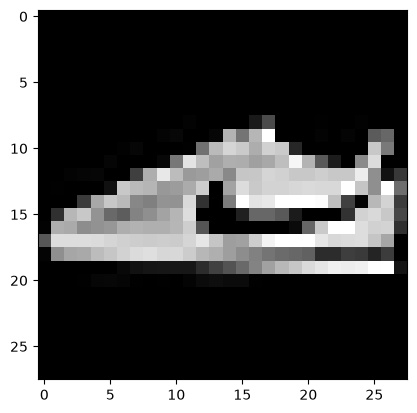

In [166]:
model.eval()

images, labels = next(iter(test_dataloader))
image, true_label = images[0], labels[0]
with torch.no_grad():
    logits = model(image.unsqueeze(0))
    prediction = logits.argmax(dim=1).item()

print("Predicted:", test_data.classes[prediction])
print("Actual:   ", test_data.classes[true_label])

plt.imshow(image.squeeze(), cmap="gray")
plt.show()